# Instellation sweep: how much CO₂ keeps an anoxic Archean Earth at 288 K?

This notebook extends the two single-case notebooks (`archean_photochem_climate.ipynb`, Sun at 3 Ga, and `archean_photochem_climate_gj876.ipynb`, the M dwarf GJ 876). It keeps the same planet, atmosphere, surface fluxes and coupled climate–photochemistry model, and sweeps the **instellation from 1400 to 300 W/m²** in 9 steps for both stars. At every step the **CO₂ partial pressure is adjusted so that the surface temperature stays at 288 K**.

For each point it reports the instellation, surface temperature, total surface pressure, and the surface volume mixing ratios of CO₂, CO, O₂ and H₂O.

**Spectra.** At each instellation the star's spectrum is rescaled to that total flux, so the spectral *shape* stays fixed: the Sun's 3 Ga spectrum, and the observed MUSCLES spectrum of GJ 876.

**Method.** For one star and instellation, the loop is:

1. Climate model: find the CO₂ pressure that gives 288 K for the current guess of CH₄ and H₂ (a fast approximate solve to bracket the answer, then Newton-like refinement against the full radiative–convective model).
2. Photochemical model: run to steady state with that CO₂ pressure and temperature profile.
3. Update CH₄ and H₂ from the photochemistry and repeat until the CO₂ pressure changes by less than about 5%.

Points are independent (each starts from scratch), so they run in parallel and each is checkpointed to a small JSON file. Re-running the notebook skips finished points.

**What to expect.**

- **288 K is not always reachable.** For some points no amount of CO₂ (up to the 10 bar cap used here) holds 288 K: the surface cannot be warmed enough (CO₂ condenses and Rayleigh scattering stops further warming at low instellation), or, for GJ 876 at the highest instellation, cannot be cooled enough. For the cold case the notebook uses the CO₂ pressure giving the *warmest* surface and flags the row `288 K not reachable`; the surface-temperature column shows the shortfall.
- **Some points have no steady state.** With this chemistry network there is no haze sink for hydrocarbons, so when CO₂ is very low (little oxidant) carbon from the CH₄ flux piles up as C₄H₄ without bound. These rows are flagged `NO STEADY STATE` and are left out of the plots and CSV values.
- **How long it takes.** The saved results took about an hour on 4 cores. A point takes from several minutes to about 35 minutes. They are cached in `sweep_results/`, so re-running the notebook just reloads them; delete that folder to recompute.
- Same caveats as the earlier notebooks: illustrative round-number surface fluxes, no organic haze, fixed N₂ pressure, fixed surface albedo.

## 1. Environment

Photochem is on **conda-forge** (not PyPI). From a bare conda install, use the `environment.yml` next to this notebook:

```sh
conda env create -f environment.yml
conda activate photochem-env
jupyter lab
```

The GJ 876 spectrum is downloaded from the MAST archive (internet access needed, once; it is cached in `sweep_runs/`).

In [1]:
import os, json, time, glob
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import matplotlib.pyplot as plt

import photochem
print("Photochem version:", photochem.__version__)

# ---- configuration ----
S_values = np.linspace(1400.0, 300.0, 9)      # instellation (W/m^2): 9 steps from 1400 to 300
stars_to_run = ["Sun", "GJ876"]                # Sun = 3 Ga spectrum; GJ876 = M dwarf (MUSCLES)
N_WORKERS = min(4, os.cpu_count() or 1)        # points run in parallel, one per worker
workdir, results_dir = "sweep_runs", "sweep_results"

Photochem version: 0.9.1


## 2. Helper library

The model code lives in `sweeplib.py`, which the next cell writes next to the notebook (so worker processes can import it on any operating system). It is long but self-contained; the key pieces are:

- `setup_files`: reaction network, boundary conditions and settings (identical to the earlier notebooks).
- `Point.solve_pCO2`: the CO₂ solver for the climate model.
- `photochem_steady`: runs the photochemistry to a *practical* steady state. Photochem's own criterion can keep integrating to 10¹⁷ s long after the composition has stopped changing (seen for GJ 876), so a point is also treated as steady when the surface mixing ratios of CO₂, CO, O₂, H₂O, CH₄ and H₂ change by under 1% over the last decade in model time. Each result records which rule stopped it.
- `run_point`: the coupling loop for one star and instellation. It sets the photochemical integrator's absolute tolerance to 10⁻¹⁸ (Photochem's default is 10⁻²³). The default made cold, CO₂-rich cases millions of times slower, because it forces tiny time steps to resolve ultra-trace species, and nothing reported here is below 10⁻¹⁸. Seven points that were run with both tolerances agreed to about four significant figures.

In [2]:
%%writefile sweeplib.py
"""Helpers for the instellation sweep notebook (written by the notebook, importable).

For a given star and instellation S, `run_point` finds the CO2 partial pressure that holds the
surface temperature at T_target in a coupled climate-photochemistry model of an anoxic planet.
"""
import os, json, time
import numpy as np
import yaml
from scipy.optimize import brentq
from photochem import EvoAtmosphere
from photochem.clima import AdiabatClimate
from photochem.utils import (stars, zahnle_rx_and_thermo_files,
                             species_file_for_climate, settings_file_for_climate)

planet_mass, planet_radius, surface_albedo = 5.972e27, 6.371e8, 0.2
relative_humidity = 0.5
T_target = 288.0                      # K
pN2_bar = 1.0
pCO2_min_bar, pCO2_max_bar = 1.0e-5, 10.0

def setup_files(workdir):
    os.makedirs(workdir, exist_ok=True)
    mech = f"{workdir}/mechanism.yaml"
    zahnle_rx_and_thermo_files(atoms_names=["H","He","N","O","C","S"], rxns_filename=mech,
                               thermo_filename=None, remove_reaction_particles=True)
    def bc(name, lower, upper=None):
        return {"name": name, "lower-boundary": lower, "upper-boundary": upper or {"type":"veff","veff":0.0}}
    def src(vdep, flux): return {"type":"vdep + dist flux","vdep":vdep,"flux":flux,"height":-1.0}
    bcs = [bc("H2O",{"type":"press","press":270.0e6}), bc("N2",{"type":"press","press":pN2_bar*1e6}),
           bc("CO2",{"type":"press","press":0.01e6}), bc("O2",{"type":"flux","flux":0.0}),
           bc("H2",src(0.0,3.0e10)), bc("CH4",{"type":"flux","flux":3.0e10}),
           bc("CO",src(1.0e-8,1.0e9)), bc("SO2",src(1.0,1.0e9)), bc("H2S",src(0.015,1.0e8)),
           bc("OCS",src(0.003,5.0e7)), bc("NO",src(0.01,3.0e8)),
           bc("NO2",{"type":"vdep","vdep":0.05}), bc("NO3",{"type":"vdep","vdep":0.05}),
           bc("HNO3",{"type":"vdep","vdep":4.0}), bc("NH3",src(1.0,1.5e10)),
           bc("H2SO4",src(1.0,7.0e8)), bc("HCN",src(0.13,1.7e8)), bc("CH3CN",src(0.13,1.3e8)),
           bc("N2O",src(0.0,0.0))]
    settings = {"atmosphere-grid":{"number-of-layers":100},
                "planet":{"planet-mass":planet_mass,"planet-radius":planet_radius,"surface-albedo":surface_albedo,
                          "solar-zenith-angle":60.0,"hydrogen-escape":{"type":"diffusion limited"},
                          "water":{"gas-rainout":True,"rainfall-rate":1,"tropopause-altitude":1.1e6}},
                "particles":[{"name":"H2Oaer","RH-condensation":relative_humidity}],
                "boundary-conditions":bcs}
    with open(f"{workdir}/photochem_settings.yaml","w") as f: yaml.safe_dump(settings,f,sort_keys=False)
    species_file_for_climate(f"{workdir}/climate_species.yaml",["H2O","CO2","N2","CH4","H2"],["H2O","CO2"])
    settings_file_for_climate(f"{workdir}/climate_settings.yaml",planet_mass,planet_radius,surface_albedo)
    return mech

def cache_stellar_spectrum(star, workdir):
    "Download an observed MUSCLES spectrum once and cache it (needs internet access)."
    path = f"{workdir}/{star}_muscles_raw.npz"
    if not os.path.exists(path):
        wv, F = stars.get_muscles_spectrum(star, False, 1000)
        np.savez(path, wv=wv, F=F)
    return path

def write_flux_file(star, S, path, workdir=None):
    "Spectrum of `star` scaled so total instellation is S (W/m^2)."
    if star == "Sun":
        stars.solar_spectrum(outputfile=path, age=3.0, stellar_flux=S, scale_before_age=False)
    else:
        d = np.load(cache_stellar_spectrum(star, workdir))
        F = stars.scale_spectrum_to_planet(d["wv"], d["F"], None, S)
        wv, F = stars.rebin_to_needed_resolution(d["wv"], F)
        stars.save_photochem_spectrum(wv, F, path, scale_to_planet=False)

def eddy_diffusion(P_bar):
    return np.where(P_bar > 0.1, 1.0e5, np.minimum(1.0e5*(0.1/P_bar)**0.5, 1.0e7))

class Point:
    "Climate model + helpers for one instellation."
    def __init__(self, workdir, flux_file):
        self.clim = AdiabatClimate(f"{workdir}/climate_species.yaml", f"{workdir}/climate_settings.yaml", flux_file)
        self.clim.verbose = False
        self.names = self.clim.species_names
        self.clim.RH = np.full(len(self.names), relative_humidity)
        self.clim.T_trop = 200.0
    def partial_pressures(self, pCO2_bar, f_CH4, f_H2):
        p_dry = (pN2_bar + pCO2_bar) / (1.0 - f_CH4 - f_H2)
        d = {"N2":pN2_bar, "CO2":pCO2_bar, "CH4":f_CH4*p_dry, "H2":f_H2*p_dry, "H2O":270.0}
        return np.array([d.get(n,1e-15) for n in self.names])*1e6
    def approx_T(self, pCO2_bar, f_CH4, f_H2):
        "Fast approximate climate (adiabat + isothermal stratosphere, solved tropopause). None if the solver fails."
        c = self.clim; c.solve_for_T_trop = True
        P_i = self.partial_pressures(pCO2_bar, f_CH4, f_H2)
        for guess in (288.0, 230.0, 340.0, 260.0):
            for T_trop in (200.0, 150.0):
                c.T_trop = T_trop
                try:
                    return c.surface_temperature(P_i, T_guess=guess)
                except Exception:
                    pass
        return None
    def rce_T(self, pCO2_bar, f_CH4, f_H2):
        "Full radiative-convective equilibrium started from the approximate solution. (T_surf, converged)."
        T0 = self.approx_T(pCO2_bar, f_CH4, f_H2)
        if T0 is None: return None, False
        c = self.clim; P_i = self.partial_pressures(pCO2_bar, f_CH4, f_H2)
        try:
            ok = c.RCE(P_i, c.T_surf, c.T, c.convecting_with_below)
        except Exception:
            ok = False
        if not ok:
            c.surface_temperature(P_i, T_guess=T0)   # restore the approximate state
            return T0, False
        return c.T_surf, True
    def solve_pCO2(self, f_CH4, f_H2, tol_K=0.25, max_refine=5):
        "pCO2 (bar) giving T_surf = T_target in the full RCE model. Returns (pCO2, status)."
        lo, hi = np.log10(pCO2_min_bar), np.log10(pCO2_max_bar)
        def fa(x):
            T = self.approx_T(10**x, f_CH4, f_H2)
            return np.nan if T is None else T - T_target
        xs = np.linspace(lo, hi, 25); ts = np.array([fa(x) for x in xs])
        good = np.isfinite(ts)
        if good[0] and ts[0] > 0:
            return 10**lo, "target not reachable: too warm even at minimum CO2"
        idx = [i for i in range(len(xs)-1) if good[i] and good[i+1] and ts[i] <= 0 <= ts[i+1]]
        if not idx:
            # 288 K is out of reach: use the CO2 that gives the warmest surface (maximum greenhouse)
            xbest = xs[int(np.nanargmax(np.where(good, ts, -np.inf)))]
            xf = np.linspace(max(lo, xbest-0.3), min(hi, xbest+0.3), 7)
            tf = np.array([fa(x) for x in xf]); xbest = xf[int(np.nanargmax(np.where(np.isfinite(tf), tf, -np.inf)))]
            return 10**xbest, "target not reachable: maximum-greenhouse CO2 used"
        i = idx[0]
        x = brentq(fa, xs[i], xs[i+1], xtol=0.002)
        # refine against the full RCE model with Newton-like steps
        for _ in range(max_refine):
            T, ok = self.rce_T(10**x, f_CH4, f_H2)
            if T is None: break
            err = T - T_target
            if abs(err) < tol_K: break
            d = 0.05
            Ta, Tb = self.approx_T(10**(x-d), f_CH4, f_H2), self.approx_T(10**(x+d), f_CH4, f_H2)
            slope = (Tb - Ta) / (2*d) if (Ta is not None and Tb is not None) else 40.0
            slope = max(slope, 5.0)
            x = float(np.clip(x - err/slope, lo, hi))
        return 10**x, "ok"

def photochem_steady(pc, tracked, tol=0.01, trace_floor=1e-12, trace_dex=0.05, min_time=1e12, decade=10.0,
                     check_every=25, max_wall=7200, runaway_vmr=5e-3,
                     expected=("N2", "CO2", "H2O", "H2", "CO", "CH4", "He")):
    """Integrate to a practical steady state.
    Steady = Photochem's own criterion, OR the surface mixing ratios of the `tracked` species
    changed by less than `tol` (1%) over the last decade in model time (and t > min_time).
    Trace species (mixing ratio < trace_floor, e.g. O2 at 1e-16) are instead compared in log space
    (change < trace_dex dex), since their relative noise is large and they do not matter physically.
    Also stops early with reason "runaway: <species>" if a gas other than the expected major/minor
    species exceeds `runaway_vmr` at the surface: in these runs hydrocarbons such as C4H4 can pile up
    without bound when there is little oxidant, because haze formation is not modelled, so no steady
    state exists.
    Returns (reason, model time, steps, wall time, species limiting convergence)."""
    pc.var.nsteps_before_giveup = 1000000       # the default (1e5) can be exhausted before steady state
    pc.initialize_robust_stepper(pc.wrk.usol)
    hist = []; n = 0; t0 = time.time(); reason = "max wall time"; worst = ""
    def surf():
        a = pc.mole_fraction_dict(); return np.array([a[s][0] for s in tracked])
    while True:
        give_up, conv = pc.robust_step(); n += 1
        if conv: reason = "photochem criterion"; break
        if give_up: reason = "give_up"; break
        if n % check_every == 0:
            tn = pc.wrk.tn; v = surf(); hist.append((tn, v))
            if n % (4*check_every) == 0:
                a = pc.mole_fraction_dict()
                bad = [(a[k][0], k) for k in pc.dat.species_names[:pc.dat.nq]
                       if k not in expected and not k.endswith("aer") and a[k][0] > runaway_vmr]
                if bad:
                    worst = max(bad)[1]; reason = f"runaway: {worst} accumulating"; break
            if tn > min_time:
                old = [h for h in hist if h[0] <= tn/decade]
                if old:
                    v0 = old[-1][1]
                    tiny = (np.abs(v) < trace_floor) & (np.abs(v0) < trace_floor)
                    rel = np.abs(v - v0) / np.maximum(np.maximum(np.abs(v), np.abs(v0)), 1e-300)
                    dex = np.abs(np.log10(np.maximum(np.abs(v), 1e-300)) - np.log10(np.maximum(np.abs(v0), 1e-300)))
                    score = np.where(tiny, dex/trace_dex, rel/tol)      # < 1 means converged
                    worst = tracked[int(np.argmax(score))]
                    if score.max() < 1.0: reason = "composition steady over last decade"; break
        if time.time() - t0 > max_wall: break
    pc.destroy_stepper()
    return reason, pc.wrk.tn, n, time.time() - t0, worst

def surface_summary(pc):
    a = pc.mole_fraction_dict()
    return {k: float(a[k][0]) for k in ["CO2","CO","O2","H2O","CH4","H2","N2"]}

def run_point(star, S, workdir, results_dir, max_iter=6, dlog_tol=0.02, max_wall_s=10800, log=print):
    """One sweep point: find the CO2 that gives T_surf = T_target for a coupled
    climate-photochemistry model at instellation S, starting from scratch.
    Result is checkpointed to results_dir/{star}_S{S}.json and returned."""
    os.makedirs(results_dir, exist_ok=True)
    path = f"{results_dir}/{star}_S{S:.1f}.json"
    if os.path.exists(path):
        return json.load(open(path))
    t_point = time.time()
    tag = f"{star} S={S:.1f}"
    pdir = f"{workdir}/{star}_S{S:.1f}"; os.makedirs(pdir, exist_ok=True)
    for f in ["mechanism.yaml", "photochem_settings.yaml", "climate_species.yaml", "climate_settings.yaml"]:
        if not os.path.exists(f"{pdir}/{f}"): os.symlink(os.path.abspath(f"{workdir}/{f}"), f"{pdir}/{f}")
    flux_file = f"{pdir}/flux.txt"; write_flux_file(star, S, flux_file, workdir)
    pt = Point(pdir, flux_file)
    tracked = ["CO", "O2", "H2O", "CH4", "H2", "CO2"]
    f_CH4, f_H2 = 1.0e-5, 1.0e-3          # first guess for the radiatively active trace gases
    pc = None; history = []
    for it in range(max_iter):
        pCO2, status = pt.solve_pCO2(f_CH4, f_H2)
        T_rce, rce_ok = pt.rce_T(pCO2, f_CH4, f_H2)
        c = pt.clim; P = np.append(c.P_surf, c.P); T = np.append(c.T_surf, c.T)
        if pc is None:
            pc = EvoAtmosphere(f"{pdir}/mechanism.yaml", f"{pdir}/photochem_settings.yaml", flux_file)
            pc.var.verbose = 0
            # Absolute tolerance in mixing ratio. The default (1e-23) forces tiny time steps in cold, CO2-rich
            # atmospheres (10^6 times slower to reach steady state); 1e-18 is far below anything reported.
            pc.var.atol = 1.0e-18
            pc.set_lower_bc("CO2", "press", press=pCO2*1e6)
            pc.initialize_atmosphere_p(P, T, eddy_diffusion(P/1e6), mix=None,
                particle_radius={"H2Oaer": np.full(P.size, 1.0e-3)}, persistent=True,
                tropopause_pressure=float(c.P_trop), target_pressure=P[-1])
        else:
            pc.set_lower_bc("CO2", "press", press=pCO2*1e6)
            pc.set_press_temp_edd_profile(P, T, eddy_diffusion(P/1e6), trop_p=float(c.P_trop),
                hydro_pressure=True, maintain_toa_pressure=True, target_pressure=P[-1])
        reason, tn, nsteps, wall, worst = photochem_steady(pc, tracked, max_wall=max_wall_s)
        steady = reason in ("photochem criterion", "composition steady over last decade")
        sm = surface_summary(pc); f_CH4, f_H2 = sm["CH4"], sm["H2"]
        history.append({"pCO2_bar": pCO2, "T_rce_K": T_rce, "photochem_stop": reason, "photochem_t_s": tn, "photochem_wall_s": wall, "limiting_species": worst})
        log(f"[{tag}] iter {it}: pCO2={pCO2:.4g} bar ({status}), T(RCE)={T_rce:.2f} K, photochem: {reason} "
            f"(t={tn:.1e} s, {wall:.0f} s wall, limiting: {worst}), CO={sm['CO']:.2e} CH4={sm['CH4']:.2e} H2={sm['H2']:.2e}")
        if reason.startswith("runaway"):
            pCO2_next = pCO2; break          # no steady state exists, so there is nothing to iterate on
        pCO2_next, status_next = pt.solve_pCO2(f_CH4, f_H2)
        if abs(np.log10(pCO2_next/pCO2)) < dlog_tol: break
    converged = (not reason.startswith("runaway")) and abs(np.log10(pCO2_next/pCO2)) < dlog_tol
    T_final, rce_ok = pt.rce_T(pCO2, f_CH4, f_H2)      # climate for the final composition, at the CO2 used
    sm = surface_summary(pc)
    result = {"star": star, "S_Wm2": S, "T_surf_K": float(T_final), "rce_converged": bool(rce_ok),
              "pCO2_bar": float(pCO2), "P_total_bar": float(pc.wrk.surface_pressure), "vmr": sm,
              "target_status": status, "coupling_converged": bool(converged), "iterations": it+1,
              "photochem_stop": reason, "photochem_steady": bool(steady), "wall_s": time.time()-t_point, "history": history}
    json.dump(result, open(path, "w"), indent=1)
    log(f"[{tag}] DONE: T={T_final:.2f} K pCO2={pCO2:.4g} bar Ptot={pc.wrk.surface_pressure:.3f} bar "
        f"converged={converged} ({time.time()-t_point:.0f} s)")
    return result

def worker(args):
    "Run one (star, S) point in a worker process; progress is appended to <workdir>/sweep.log."
    os.environ["OMP_NUM_THREADS"] = "1"
    star, S, workdir, results_dir = args
    def log(msg):
        print(msg, flush=True)
        with open(f"{workdir}/sweep.log", "a") as f: f.write(msg + "\n")
    return run_point(star, S, workdir, results_dir, log=log)

Writing sweeplib.py


In [3]:
from sweeplib import *

setup_files(workdir)                            # network, boundary conditions, climate-model files
if "GJ876" in stars_to_run:
    cache_stellar_spectrum("GJ876", workdir)    # one download of the GJ 876 spectrum, cached

## 3. Run the sweep

Skips any point that already has a result file in `sweep_results/`. Progress is appended to `sweep_runs/sweep.log`.

In [4]:
jobs = [(star, float(S), workdir, results_dir) for star in stars_to_run for S in S_values
        if not os.path.exists(f"{results_dir}/{star}_S{S:.1f}.json")]
jobs.sort(key=lambda j: -j[1])                  # high instellation (fast) first
print(f"{len(jobs)} of {len(stars_to_run) * len(S_values)} points still to compute")

if jobs:
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
        for result in pool.map(worker, jobs):
            print(f"{result['star']:6s} S={result['S_Wm2']:7.1f} W/m2: T={result['T_surf_K']:.1f} K, "
                  f"pCO2={result['pCO2_bar']:.3g} bar  ({time.time() - t0:.0f} s elapsed)")
else:
    print("All points already computed; loading cached results.")

0 of 18 points still to compute
All points already computed; loading cached results.


## 4. Results

In [5]:
results = {star: [] for star in stars_to_run}
for path in sorted(glob.glob(f"{results_dir}/*.json")):
    r = json.load(open(path))
    if r["star"] in results:
        results[r["star"]].append(r)
for star in results:
    results[star].sort(key=lambda r: -r["S_Wm2"])

def runaway(r):
    return r["photochem_stop"].startswith("runaway")

def flag(r):
    notes = []
    if runaway(r): return "NO STEADY STATE: " + r["photochem_stop"].replace("runaway: ", "")
    if r["target_status"] != "ok": notes.append("288 K not reachable")
    if not r["photochem_steady"]: notes.append("photochem not steady (" + r["photochem_stop"] + ")")
    if not r["coupling_converged"]: notes.append("CO2 not converged")
    if not r["rce_converged"]: notes.append("approx. climate")
    return "; ".join(notes)

header = (f"{'S (W/m2)':>9} {'T_surf (K)':>11} {'P_tot (bar)':>12} {'pCO2 set':>9} {'CO2':>10} {'CO':>10} {'O2':>10} {'H2O':>10}  notes")
for star in stars_to_run:
    print(f"\n=== {star} ===  (volume mixing ratios at the surface; pCO2 set = CO2 partial pressure in bar the model was given)")
    print(header)
    for r in results[star]:
        if runaway(r):
            print(f"{r['S_Wm2']:9.1f} {'--':>11} {'--':>12} {r['pCO2_bar']:9.3g} {'--':>10} {'--':>10} {'--':>10} {'--':>10}  {flag(r)}")
            continue
        v = r["vmr"]
        print(f"{r['S_Wm2']:9.1f} {r['T_surf_K']:11.1f} {r['P_total_bar']:12.3f} {r['pCO2_bar']:9.3g} {v['CO2']:10.2e} "
              f"{v['CO']:10.2e} {v['O2']:10.2e} {v['H2O']:10.2e}  {flag(r)}")


=== Sun ===  (volume mixing ratios at the surface; pCO2 set = CO2 partial pressure in bar the model was given)
 S (W/m2)  T_surf (K)  P_tot (bar)  pCO2 set        CO2         CO         O2        H2O  notes
   1400.0       287.9        1.051  4.65e-05   4.59e-05   1.66e-06   9.68e-15   8.06e-03  
   1262.5       287.7        1.051   0.00109   1.08e-03   1.58e-05   5.02e-15   8.08e-03  
   1125.0       288.3        1.064    0.0129   1.26e-02   8.26e-05   4.03e-15   8.17e-03  
    987.5       288.2        1.126    0.0732   6.73e-02   4.23e-04   3.51e-15   7.66e-03  
    850.0       287.4        1.388     0.306   2.29e-01   1.52e-02   2.20e-16   6.55e-03  
    712.5       287.8        2.294      1.16   5.24e-01   1.65e-02   1.29e-17   4.03e-03  
    575.0       288.0        4.672      3.43   7.64e-01   8.08e-03   1.19e-18   1.93e-03  
    437.5       222.5       11.646        10   9.04e-01   3.40e-03   1.53e-18   2.38e-05  288 K not reachable
    300.0       188.1        1.957        10 

In [6]:
# Also save a flat table next to the notebook
import csv
with open("instellation_sweep_results.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["star", "S_Wm2", "T_surf_K", "P_total_bar", "pCO2_bar", "vmr_CO2", "vmr_CO", "vmr_O2", "vmr_H2O",
                "target_reached", "photochem_steady", "coupling_converged"])
    for star in stars_to_run:
        for r in results[star]:
            if runaway(r):
                w.writerow([star, r["S_Wm2"], "", "", r["pCO2_bar"], "", "", "", "", r["target_status"] == "ok", False, False])
                continue
            v = r["vmr"]
            w.writerow([star, r["S_Wm2"], round(r["T_surf_K"], 2), round(r["P_total_bar"], 4), r["pCO2_bar"],
                        v["CO2"], v["CO"], v["O2"], v["H2O"], r["target_status"] == "ok",
                        r["photochem_steady"], r["coupling_converged"]])
print("wrote instellation_sweep_results.csv")

wrote instellation_sweep_results.csv


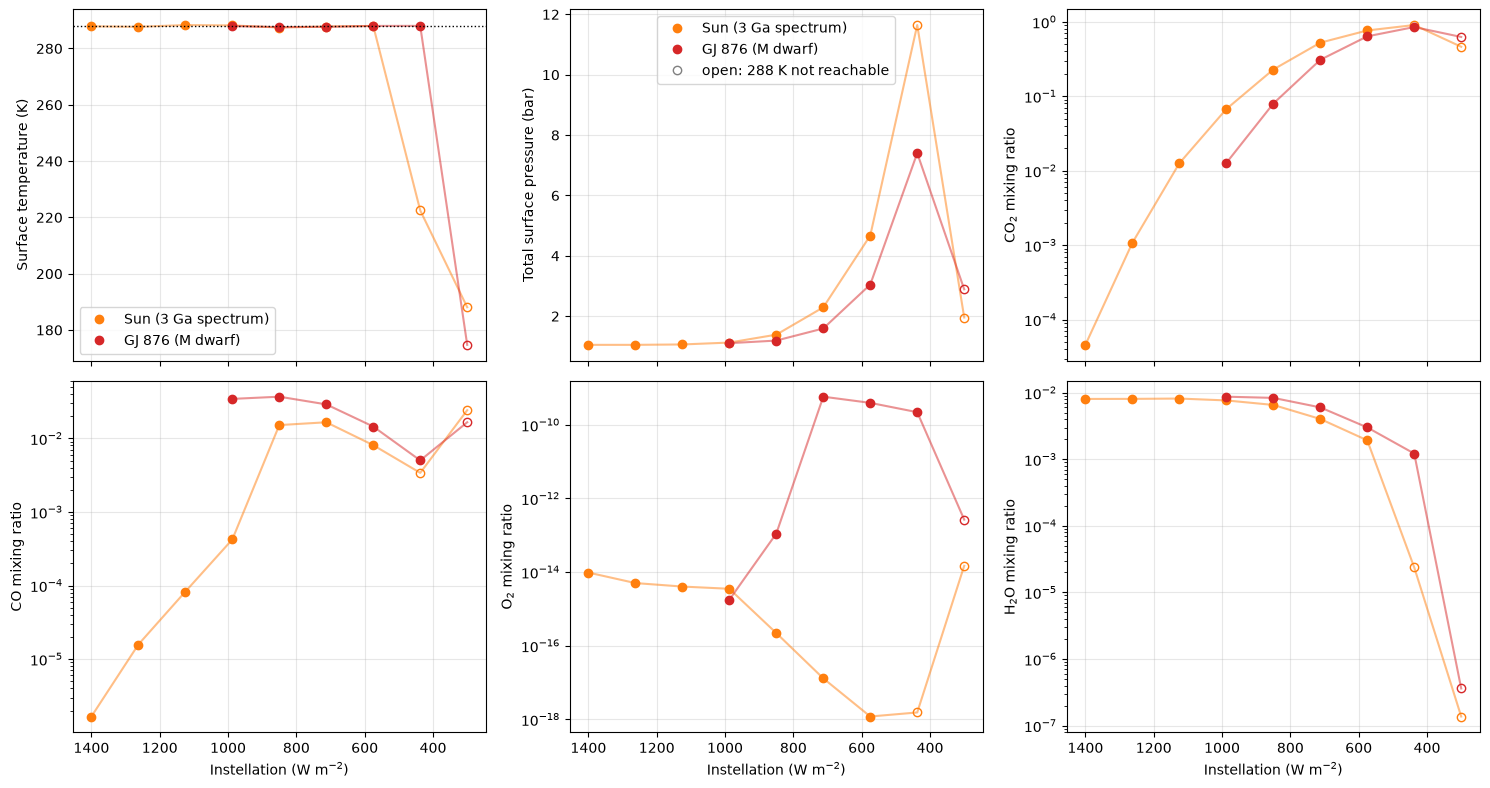

In [7]:
colors = {"Sun": "C1", "GJ876": "C3"}
labels = {"Sun": "Sun (3 Ga spectrum)", "GJ876": "GJ 876 (M dwarf)"}
panels = [("T_surf_K", "Surface temperature (K)", False),
          ("P_total_bar", "Total surface pressure (bar)", False),
          ("CO2", "CO$_2$ mixing ratio", True),
          ("CO", "CO mixing ratio", True),
          ("O2", "O$_2$ mixing ratio", True),
          ("H2O", "H$_2$O mixing ratio", True)]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, (key, ylabel, log) in zip(axes.flat, panels):
    for star in stars_to_run:
        rs = [r for r in results[star] if not runaway(r)]      # runaway points have no steady state
        if not rs: continue
        S = np.array([r["S_Wm2"] for r in rs])
        y = np.array([r[key] if key in r else r["vmr"][key] for r in rs])
        ok = np.array([r["target_status"] == "ok" for r in rs])
        ax.plot(S, y, "-", color=colors[star], alpha=0.5)
        ax.plot(S[ok], y[ok], "o", color=colors[star], label=labels[star])
        ax.plot(S[~ok], y[~ok], "o", mfc="none", color=colors[star])   # open = 288 K not reachable
    if log: ax.set_yscale("log")
    ax.set_ylabel(ylabel); ax.grid(alpha=0.3)
    if key == "T_surf_K": ax.axhline(288, color="k", ls=":", lw=1)
for ax in axes[1]: ax.set_xlabel("Instellation (W m$^{-2}$)")
axes[0, 0].legend()
axes[0, 1].plot([], [], "o", mfc="none", color="gray", label="open: 288 K not reachable"); axes[0, 1].legend(loc="upper center")
axes[0, 0].invert_xaxis()
plt.tight_layout(); plt.show()

### Reading the results

These numbers come from a single run of this notebook (saved in `sweep_results/`). The comparisons below are read off the table; explanations of *why* are hypotheses that I have not tested.

**What it takes to hold 288 K**

| Instellation (W/m²) | Sun, 3 Ga spectrum | GJ 876 |
|---|---|---|
| 1400 | ~5×10⁻⁵ bar CO₂ | no steady state; 288 K not reachable (hotter even at minimum CO₂) |
| 1262.5 | ~1×10⁻³ bar | no steady state |
| 1125 | ~0.013 bar | no steady state |
| 987.5 | ~0.07 bar | ~0.014 bar |
| 850 | ~0.31 bar | ~0.09 bar |
| 712.5 | ~1.2 bar | ~0.47 bar |
| 575 | ~3.4 bar | ~1.9 bar |
| 437.5 | not reachable (222 K at 10 bar) | ~6.0 bar |
| 300 | not reachable (188 K) | not reachable (175 K) |

- **The required CO₂ climbs by about five orders of magnitude** across the range for the Sun, and total pressure reaches about 4.7 bar (Sun, 575 W/m²) and 7.4 bar (GJ 876, 437.5 W/m²).
- **At the same instellation, the M dwarf needs less CO₂ to stay at 288 K** wherever both are steady (by roughly a factor of 2 to 5), and it reaches 288 K at a lower instellation (437.5 W/m² versus 575). A plausible reason is the M dwarf's redder spectrum (more energy where H₂O, CO₂ and CH₄ absorb, less lost to Rayleigh scattering), but this notebook does not separate the causes.
- **CO is much higher around GJ 876** (about 0.5–4% at the points that hold 288 K, versus 2×10⁻⁶ to 2×10⁻² for the Sun), as in the single-case notebooks. **O₂ is also higher around GJ 876 at high CO₂** (up to ~6×10⁻¹⁰ versus at most ~10⁻¹⁴ for the Sun), still negligible. Both fit weaker near-UV photolysis giving less OH, and CO₂ photolysis becoming the main oxygen source, but I have not checked that.
- **H₂O falls steadily** as the instellation drops: across the points that hold 288 K, the surface mixing ratio goes from about 0.8% to 0.1–0.2% (the total pressure rises, and the troposphere and cold trap get colder).

**Caveats on specific points**

- **GJ 876 at 1400, 1262.5 and 1125 W/m² have no steady state.** CO₂ is very low there, and with this network (no haze formation) C₄H₄ accumulates without bound. In the real world that carbon would form haze. These rows are left out of the plots; their CO₂ pressures in the table are the values attempted.
- **The "288 K not reachable" cold points are given 10 bar of CO₂.** At 300 W/m² the resulting surface pressure is only 2–3 bar, so most of that CO₂ has condensed out. At 437.5 W/m² the Sun case keeps all of it as vapour (11.6 bar total) at 222 K. These rows describe the maximum-greenhouse cold limit, not a tuned atmosphere.
- Fixed albedo (0.2), fixed 1 bar of N₂ and a single set of round-number surface fluxes were used throughout. Heavier CO₂ atmospheres would also change the albedo, which is not modelled.